## Práctica 03: Series de Fourier: Magnitud y fase

Sofía Cedeño Vargas, 
Mariana Paulina Vargas

### Crear la señal cuadrada

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros de la señal
f0 = 1          # Frecuencia fundamental [Hz]
A = 1           # Amplitud
N = 1000        # Número de muestras

# Periodo fundamental
T0 = 1 / f0

# Vector de tiempo: un periodo
t = np.linspace(0, T0, N, endpoint=False)

# Señal cuadrada
x_cuadrada = A * np.where(np.sin(2 * np.pi * f0 * t) >= 0, 1, -1)

print("Frecuencia fundamental:", f0, "Hz")
print("Periodo:", T0, "s")
print("Amplitud:", A)
print("Número de muestras:", N)
print("Primeras 10 muestras:", x_cuadrada[:10])

Frecuencia fundamental: 1 Hz
Periodo: 1.0 s
Amplitud: 1
Número de muestras: 1000
Primeras 10 muestras: [1 1 1 1 1 1 1 1 1 1]


### Construir la señal triangular

In [2]:
# Señal triangular con los mismos parámetros
x_triangular = (2 * A / np.pi) * np.arcsin(
    np.sin(2 * np.pi * f0 * t)
)

print("Frecuencia fundamental:", f0, "Hz")
print("Periodo:", T0, "s")
print("Amplitud máxima:", np.max(x_triangular))
print("Amplitud mínima:", np.min(x_triangular))
print("Número de muestras:", len(x_triangular))
print("Primeras 10 muestras:", x_triangular[:10])

Frecuencia fundamental: 1 Hz
Periodo: 1.0 s
Amplitud máxima: 1.0
Amplitud mínima: -1.0
Número de muestras: 1000
Primeras 10 muestras: [0.    0.004 0.008 0.012 0.016 0.02  0.024 0.028 0.032 0.036]


### Graficar ambas señales

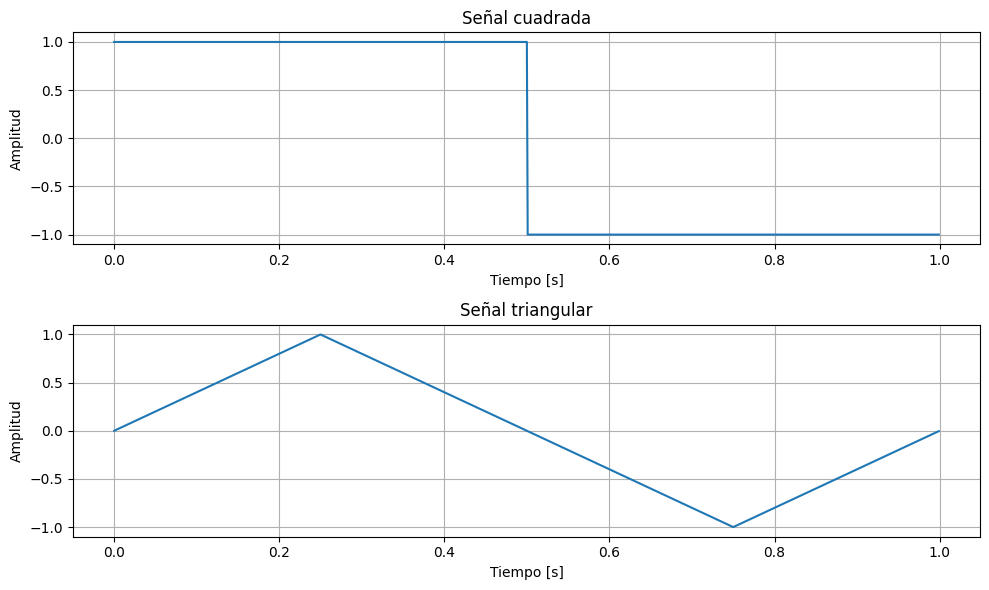

In [3]:
plt.figure(figsize=(10, 6))

# Señal cuadrada
plt.subplot(2, 1, 1)
plt.plot(t, x_cuadrada)
plt.title("Señal cuadrada")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)

# Señal triangular
plt.subplot(2, 1, 2)
plt.plot(t, x_triangular)
plt.title("Señal triangular")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()

### Función para calcular los coeficientes de Fourier

In [4]:
def coeficientes_fourier(x):
    """
    Calcula los coeficientes de la serie de Fourier
    exponencial de una señal periódica.
    """
    
    N = len(x)
    
    # FFT normalizada por el número de muestras
    coeficientes = np.fft.fft(x) / N
    
    # Centrar los coeficientes:
    # frecuencias negativas - cero - frecuencias positivas
    coeficientes = np.fft.fftshift(coeficientes)
    
    return coeficientes


print("Función creada correctamente.")

Función creada correctamente.


### Calcular los coeficientes de ambas señales

In [5]:
# Calcular coeficientes de Fourier
C_cuadrada = coeficientes_fourier(x_cuadrada)
C_triangular = coeficientes_fourier(x_triangular)

print("Número de coeficientes señal cuadrada:", len(C_cuadrada))
print("Número de coeficientes señal triangular:", len(C_triangular))

# Coeficiente correspondiente a n = 0
centro = N // 2

print("\nCoeficiente n=0 señal cuadrada:", C_cuadrada[centro])
print("Coeficiente n=0 señal triangular:", C_triangular[centro])

# Primer armónico positivo
print("\nPrimer armónico señal cuadrada:", C_cuadrada[centro + 1])
print("Primer armónico señal triangular:", C_triangular[centro + 1])

Número de coeficientes señal cuadrada: 1000
Número de coeficientes señal triangular: 1000

Coeficiente n=0 señal cuadrada: (0.002+0j)
Coeficiente n=0 señal triangular: (2.555148560345268e-18+0j)

Primer armónico señal cuadrada: (7.993605777301128e-18-0.6366176779711009j)
Primer armónico señal triangular: (-1.9996942520846553e-17-0.4052860679053164j)


### Función para espectros de magnitud y fase

In [6]:
def graficar_espectros(coeficientes, titulo):
    
    N = len(coeficientes)
    
    # Índices de los armónicos
    armonicos = np.arange(-N//2, N//2)
    
    # Magnitud y fase
    magnitud = np.abs(coeficientes)
    fase = np.angle(coeficientes)
    
    plt.figure(figsize=(10, 6))
    
    # Espectro de magnitud
    plt.subplot(2, 1, 1)
    plt.stem(armonicos, magnitud)
    plt.title("Espectro de magnitud - " + titulo)
    plt.xlabel("Armónico n")
    plt.ylabel("|Cₙ|")
    plt.xlim(-20, 20)
    plt.grid(True)
    
    # Espectro de fase
    plt.subplot(2, 1, 2)
    plt.stem(armonicos, fase)
    plt.title("Espectro de fase - " + titulo)
    plt.xlabel("Armónico n")
    plt.ylabel("Fase [rad]")
    plt.xlim(-20, 20)
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


print("Función de espectros creada correctamente.")

Función de espectros creada correctamente.


### Espectros de la señal cuadrada

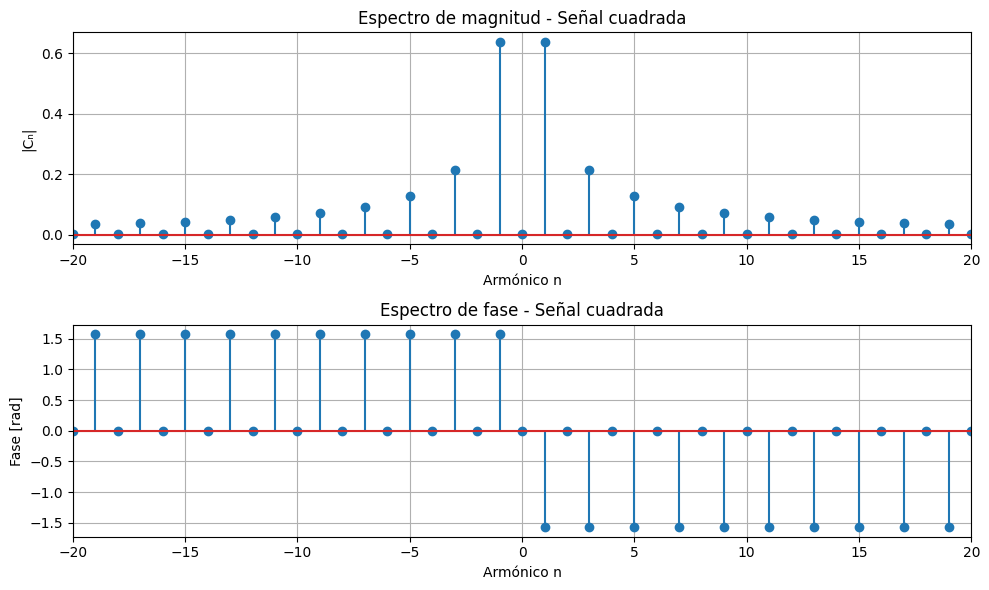

In [7]:
graficar_espectros(C_cuadrada, "Señal cuadrada")

### Señal triangular

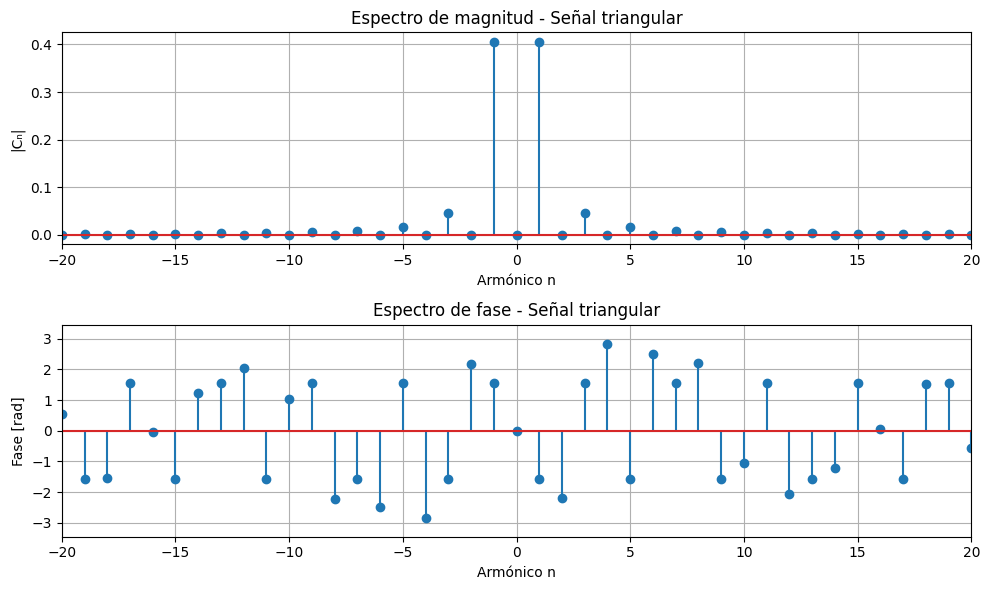

In [8]:
graficar_espectros(C_triangular, "Señal triangular")